# Case Study 1 — MSigDB-guided component selection and BoNesis optimization

**Complete pipeline:** load/standardize the original Nestorowa S0–S5 observations → load the original DoRothEA A–C network → **download the entire Mouse MSigDB** → find gene sets containing hematopoiesis-related words in their **names** → extract member genes and rank them → intersect with DoRothEA → select biological seeds → expand through regulatory neighbors and short bridges → prepare a smaller GRN → run the **original** BoNesis component-selection constraints and objectives.

This is a *modified*, seed-guided version of Chevalier et al. Case Study 1, **not an exact replication of their unrestricted component selection**. No published 39-gene list is used anywhere to select seeds.

### Requirements

- Run Jupyter from your project folder so relative paths such as `data/...` resolve.
- Keep `gene_name_standardization.py` alongside this notebook.
- The three original data files must be available:
  - `data/nestorowa_singlecell_binarized_observations.csv`
  - `data/Mus_musculus.gene_info.202103.tsv`
  - `data/dorothea_ABC_20210707_TF.sif`
- Python libraries: `pandas`, `numpy`, `networkx`, `matplotlib`, `bonesis`.
- `bash` and `clingo` are needed only if you choose to execute the optimization (ideally in WSL/Linux).

**Research question.** Chevalier et al. Case Study 1 asks which gene-regulatory subnetworks and Boolean rules can support six partially observed hematopoietic states, distinct terminal fixed points, and the specified reachability restrictions. This adaptation reduces the candidate regulatory domain using biological MSigDB seeds and data-driven neighbors *before* applying those constraints. It is therefore not a strict numerical reproduction of the paper's unrestricted component selection.

**Three separate representations are used.** (1) A **state × gene** observation matrix (`0 = OFF`, `1 = ON`, `NaN = undetermined`). (2) A signed **regulator → target** prior network, whose edges say which regulations are permitted. (3) A **Boolean update function for each gene**, which is inferred later by synthesis. A candidate gene in the SIF is not yet an inferred logical rule.


### What the notebook receives and produces

| Item | Example shape | Meaning | When consumed |
|---|---|---|---|
| Binarized Nestorowa observations | 6 × many genes | Each state contains known OFF/ON values and missing values | State constraints and observed switching scores |
| NCBI mouse gene-info TSV | alias mapping | Harmonizes gene symbols across sources | Before intersecting observations and regulation |
| DoRothEA A–C SIF | `source`, `sign`, `target` | Permitted signed regulations; direction matters | Candidate network and BoNesis influence graph |
| Mouse MSigDB GMT | many named sets × member genes | Biological annotations for prioritizing seeds, **not experimental proof** | Candidate preselection |
| Reduced SIF | up to `MAX_CANDIDATE_GENES` nodes, potentially fewer after reloading | The actual signed domain presented to component optimization | `BoNesis(small_dorothea, small_observations)` |
| Standalone `.sh` and Clingo log | generated script + solver output | Feasible choices of included nodes/strong constants; optimality depends on solver status | Subsequent component-answer ranking notebook |

## Data preprocessing <a class="anchor" id="datapreprocess"></a>

The observations used here are **already binarized**. No raw scRNA-seq normalization, threshold selection, or gene-level binarization is performed in this notebook. The file is oriented with six state labels as rows and gene symbols as columns. 

### 1. Import the observations built from single-cell data: <a class="anchor" id="import"></a>

In [1]:
import pandas as pd
import numpy as np

#### Synthetic input preview — State × gene input (synthetic)

This fake matrix makes **the row orientation and the three allowed value types** visible before loading your actual six-state CSV.

In [2]:
# DEMO ONLY: six rows representing partially observed expression profiles.
# Values are 0 (OFF), 1 (ON), and NaN (not measured / undetermined).
import pandas as pd
import numpy as np
demo_states = pd.DataFrame(
    {"TF_A": [0, 0, 1, 1, 1, 1],
     "TF_B": [1, 1, 0, np.nan, 0, 1],
     "TF_C": [np.nan, 1, 1, 0, 0, 0]},
    index=["S0", "S1", "S2", "S3", "S4", "S5"]
)
demo_states.index.name = "State"
print("SYNTHETIC state-by-gene matrix (not project data):")
display(demo_states)
print("Example state dictionary:", demo_states.to_dict(orient="index")["S2"])


SYNTHETIC state-by-gene matrix (not project data):


,TF_A,TF_B,TF_C
State,,,
S0,0,1.0,NaN
S1,0,1.0,1.0
S2,1,0.0,1.0
S3,1,NaN,0.0
S4,1,0.0,0.0
S5,1,1.0,0.0


Example state dictionary: {'TF_A': 1, 'TF_B': 0.0, 'TF_C': 1.0}


In [3]:
# Load the six pre-binarized STREAM state profiles; column 0 is the state name (S0 through S5).
df_nesto = pd.read_csv("data/nestorowa_singlecell_binarized_observations.csv", sep=",", index_col=[0])

In [4]:
df_nesto

,1110008L16Rik,1110059E24Rik,1200007C13Rik,1300017J02Rik,1500005C15Rik,1600014C10Rik,1600020E01Rik,1700006J14Rik,1700017B05Rik,1700024P16Rik,...,Zscan21,Zscan22,Zscan29,Zswim3,Zswim4,Zufsp,Zxdb,Zxdc,Zyx,Zzz3
S1,0,0,NaN,NaN,NaN,0,0,0,0,NaN,...,0,0,0,NaN,NaN,0,NaN,NaN,1,0
S4,0,1,NaN,NaN,NaN,1,0,0,0,NaN,...,0,0,0,NaN,NaN,0,NaN,NaN,1,0
S0,0,1,NaN,NaN,NaN,0,0,0,0,NaN,...,0,0,0,NaN,NaN,0,NaN,NaN,1,0
S2,0,0,NaN,NaN,NaN,1,1,0,0,NaN,...,0,0,0,NaN,NaN,0,NaN,NaN,1,0
S5,0,0,NaN,NaN,NaN,0,0,1,0,NaN,...,0,0,0,NaN,NaN,0,NaN,NaN,1,0
S3,0,0,NaN,NaN,NaN,0,0,0,1,NaN,...,0,0,0,NaN,NaN,0,NaN,NaN,1,1


In [5]:
# Convert each state row into a nested dictionary: {state: {gene: 0/1/NaN}} for BoNesis.
observations_from_singlecell_nestorowa = df_nesto.to_dict(orient="index")

In [7]:
observations_from_singlecell_nestorowa

{'S1': {'1110008L16Rik': 0,
  '1110059E24Rik': 0,
  '1200007C13Rik': nan,
  '1300017J02Rik': nan,
  '1500005C15Rik': nan,
  '1600014C10Rik': 0,
  '1600020E01Rik': 0,
  '1700006J14Rik': 0,
  '1700017B05Rik': 0,
  '1700024P16Rik': nan,
  '1700028E10Rik': nan,
  '1700029J07Rik': nan,
  '1700030K09Rik': 0,
  '1700065D16Rik': nan,
  '1700066M21Rik': nan,
  '1700096K18Rik': nan,
  '1810010H24Rik': nan,
  '1810011H11Rik': nan,
  '2010300C02Rik': nan,
  '2010315B03Rik': 0,
  '2210016F16Rik': 0,
  '2210016L21Rik': 0,
  '2310057M21Rik': 0,
  '2510009E07Rik': nan,
  '2610008E11Rik': nan,
  '2610021A01Rik': 0,
  '2610035D17Rik': 0,
  '2610044O15Rik8': 0,
  '2610301B20Rik': 0,
  '2610307P16Rik': 0,
  '2700029L08Rik': nan,
  '2810013P06Rik': 0,
  '2810021J22Rik': nan,
  '2810029C07Rik': nan,
  '2810414N06Rik': nan,
  '2810428J06Rik': nan,
  '2810468N07Rik': nan,
  '2810474O19Rik': 0,
  '2900005J15Rik': nan,
  '2900018N21Rik': nan,
  '2900092N22Rik': nan,
  '3110043O21Rik': nan,
  '3632451O06Rik': na

### 2. Standardize the observations' gene names. <a class="anchor" id="standardobs"></a>

We use the file "data/Mus_musculus.gene_info.202103.tsv" downloaded on 2021-03 from NCBI (mouse gene info).

In [8]:
import gene_name_standardization as gns

#### Synthetic input preview — Gene-name standardization (synthetic).

In [9]:
demo_aliases = {"TF-A-OLD": "TF_A", "TF_B": "TF_B", "TF-C-ALT": "TF_C"}
demo_before = {"S0": {"TF-A-OLD": 0, "TF_B": 1, "TF-C-ALT": np.nan}}
demo_after = {state: {demo_aliases.get(gene, gene): value for gene, value in genes.items()}
              for state, genes in demo_before.items()}
print("Before:", demo_before)
print("After: ", demo_after)
print("The notebook instead uses NCBI gene-info to compute real mappings.")


Before: {'S0': {'TF-A-OLD': 0, 'TF_B': 1, 'TF-C-ALT': nan}}
After:  {'S0': {'TF_A': 0, 'TF_B': 1, 'TF_C': nan}}
The notebook instead uses NCBI gene-info to compute real mappings.


In [10]:
# Standardize observed gene names using the mouse NCBI gene-info table; keep state values unchanged.
standardized_observations = gns.observations_standardization(observations_from_singlecell_nestorowa, "data/Mus_musculus.gene_info.202103.tsv")

In [12]:
# Visualisation of the matrix with standardized gene names:
# Reconstruct a DataFrame for inspection. Empty strings are visual placeholders for undetermined entries.
df_standardized = pd.DataFrame.from_dict(standardized_observations, orient="index").fillna('')
df_standardized

,PRORP,1110059E24RIK,1200007C13RIK,1300017J02RIK,1500005C15RIK,1600014C10RIK,1600020E01RIK,1700006J14RIK,1700017B05RIK,FYB2,...,ZSCAN21,ZSCAN22,ZSCAN29,ZSWIM3,ZSWIM4,ZUP1,ZXDB,ZXDC,ZYX,ZZZ3
S1,0,0,,,,0,0,0,0,,...,0,0,0,,,0,,,1,0
S4,0,1,,,,1,0,0,0,,...,0,0,0,,,0,,,1,0
S0,0,1,,,,0,0,0,0,,...,0,0,0,,,0,,,1,0
S2,0,0,,,,1,1,0,0,,...,0,0,0,,,0,,,1,0
S5,0,0,,,,0,0,1,0,,...,0,0,0,,,0,,,1,0
S3,0,0,,,,0,0,0,1,,...,0,0,0,,,0,,,1,1


In [13]:
# Genes being in this single-cell dataset.
#  Collect the unique standardized gene-symbol columns into a set for coverage comparisons.
standardized_genenames_in_singlecell = set(df_standardized)

In [14]:
# Count how many gene symbols occur in the standardized observation matrix.
len(standardized_genenames_in_singlecell)

4768

### What a signed influence graph means

Each DoRothEA SIF row is a directed regulatory possibility: `source  sign  target`, where `1` indicates a positive influence and `-1` a negative one. A row does **not** specify whether the target requires its regulator through AND, OR, or a more complex condition. BoNesis later searches for update rules compatible with these signed possibilities and the observations.

`maxclause=8` constrains the permitted clause structure; `allow_skipping_nodes=True` lets the component-selection solver omit candidate components. `canonic=False` follows the original selection stage rather than forcing the canonical network representation used later in full model synthesis. The loader can add positive self-loops for genes with no incoming regulators.


### 3. Get interaction graph from DoRothEA database. <a class="anchor" id="dorothea"></a>

Interactions of confidence A, B and C were extracted from DoRothEA on 2021-07-07. 
The extraction from DoRothEA and the standardization of the gene names were processed as described in the [tutorial](https://github.com/StephanieChevalier/notebooks_for_bonesis/blob/main/tutorials/Tutorial_for_interaction_graph_preprocessing.ipynb). 
We only kept edges from transcription factors to transcription factors or to genes with expression values in the Nestorowa single-cell dataset ([dorothea_ABC_20210707_TF.sif](https://github.com/StephanieChevalier/notebooks_for_bonesis/blob/main/applications/hematopoiesis/data/dorothea_ABC_20210707_TF.sif): 1001 nodes, 2777 edges).

**Two nested selection problems:** The present notebook first performs a fast, interpretable **heuristic restriction of the prior network** (biological seeds, graph neighbors, short paths, observed switches). It then asks **BoNesis/Clingo** to select a compatible set of model components in that smaller network. The heuristic is not itself a proof of dynamical feasibility or optimality.


## Use of BoNesis for selection of components <a class="anchor" id="bonesis"></a>

In [15]:
import bonesis

ipylab module is not installed, menus and toolbar are disabled.


In [16]:
standardized_dorothea = bonesis.InfluenceGraph.from_sif("data/dorothea_ABC_20210707_TF.sif", maxclause=8, allow_skipping_nodes=True, canonic=False)

In [18]:
# MSigDB download and gene-set matching settings
from pathlib import Path
from collections import defaultdict
import urllib.request
import shutil
import re
import json
import itertools
import networkx as nx
import matplotlib.pyplot as plt

# Specify the exact mouse MSigDB release to make the source reproducible.
MSIGDB_RELEASE = "2026.1.Mm"
# Build the local GMT filename inside data/ using the configured release.
MSIGDB_GMT = Path("data") / f"msigdb.v{MSIGDB_RELEASE}.symbols.gmt"
# Begin the multi-line official MSigDB download URL expression.
MSIGDB_URL = (
    f"https://data.broadinstitute.org/gsea-msigdb/msigdb/release/"
    f"{MSIGDB_RELEASE}/msigdb.v{MSIGDB_RELEASE}.symbols.gmt"
)

# Search across ALL Mouse MSigDB collections by default.
# The search uses gene-set NAMES 
# Start the list of case-insensitive terms used to match *gene-set names*.
SEARCH_TERMS = [
    "HEMATOPOIESIS", "HEMOPOIESIS",
    "HEMATOPOIETIC", "HEMOPOIETIC",
    "HAEMATOPOIESIS", "HAEMATOPOIETIC"
]

GO_BP_ONLY = False              # True limits matches to GOBP_ gene sets
MIN_MATCHING_SETS = 1          # Minimum number of matched sets containing a seed gene
SEED_TOP_N = 25      # Choose the highest-ranked 25 biological seeds. None would keep all eligible seeds.        

# Regulatory-neighborhood selection BEFORE BoNesis optimization
# EXPLAIN: Expand this many undirected neighborhood steps along the directed DoRothEA graph.
NEIGHBOR_HOPS = 1
# Enable inclusion of nodes on short connections between different seeds.
INCLUDE_SHORT_BRIDGES = True
# Only retain seed-to-seed shortest paths containing at most three edges.
MAX_BRIDGE_EDGES = 3
# Reserve up to 20 extra genes that change across determined state transitions.
N_EXTRA_DYNAMIC = 20
# Limit the final candidate domain before Clingo optimization to at most 150 genes.
MAX_CANDIDATE_GENES = 150

# Keep solver execution disabled: by default only export the standalone shell script.
RUN_OPTIMIZATION_IN_NOTEBOOK = False
# When execution is enabled, pass a 900-second (15-minute) time limit to Clingo.
OPTIMIZATION_TIME_LIMIT_SECONDS = 900

# Store all reports and the generated solver script in this output directory.
OUTPUT_DIR = Path("msigdb_hematopoiesis_selection")
OUTPUT_DIR.mkdir(exist_ok=True)

print("MSigDB:", MSIGDB_URL)
print("All collections:", not GO_BP_ONLY)


MSigDB: https://data.broadinstitute.org/gsea-msigdb/msigdb/release/2026.1.Mm/msigdb.v2026.1.Mm.symbols.gmt
All collections: True


## 4. Download the complete Mouse MSigDB

The official release is a **single complete GMT of mouse gene symbols**, not a GO-only subset. If the file already exists, the notebook does not download it again. An existing local file lets you rerun the notebook offline.


In [19]:
MSIGDB_GMT.parent.mkdir(parents=True, exist_ok=True)

# Download only if the GMT is absent or has zero bytes; otherwise reuse the cached file.
if not MSIGDB_GMT.exists() or MSIGDB_GMT.stat().st_size == 0:
    temp_path = MSIGDB_GMT.with_name(MSIGDB_GMT.name + ".part")
    print("Downloading:", MSIGDB_URL)
    request = urllib.request.Request(MSIGDB_URL, headers={"User-Agent": "Mozilla/5.0"})
    try:
        with urllib.request.urlopen(request, timeout=120) as response:
            with temp_path.open("wb") as destination:
                shutil.copyfileobj(response, destination)
        if temp_path.stat().st_size == 0:
            raise RuntimeError("Downloaded an empty GMT file")
        temp_path.replace(MSIGDB_GMT)
    except Exception as exc:
        temp_path.unlink(missing_ok=True)
        raise RuntimeError(
            f"Could not download MSigDB ({exc}). Download the file manually from:\n"
            f"{MSIGDB_URL}\nSave it here: {MSIGDB_GMT.resolve()}"
        ) from exc
else:
    print("Using existing local GMT")

print("GMT:", MSIGDB_GMT.resolve())
print("File size (MB):", round(MSIGDB_GMT.stat().st_size / (1024 ** 2), 2))


Using existing local GMT
GMT: /home/eren/hematopoiesis/data/msigdb.v2026.1.Mm.symbols.gmt
File size (MB): 12.03


## 5. Find hematopoiesis-related gene sets across **all** MSigDB collections

A GMT row is `gene-set name`, `description/link`, then its member genes. This code searches **the gene-set name**, not each individual gene. It collects the union of genes from every matching set and records each gene's source sets. Set `GO_BP_ONLY=True` only if you want GO Biological Process terms rather than the full collection.


In [20]:
# Initialize the counter of valid GMT rows encountered.
all_sets_count = 0
# Create a mapping from matched gene-set names to member-gene sets.
matching_sets = {}
# Create a lookup of matched set names to their description or source link.
matching_descriptions = {}
# Create a reverse map: each gene points to all matched sets containing it.
gene_to_sets = defaultdict(set)

with MSIGDB_GMT.open("r", encoding="utf-8") as handle:
    # Enumerate rows
    for line_number, line in enumerate(handle, start=1):
        # Strip the line ending and split its fields using tabs.
        columns = line.rstrip("\n\r").split("\t")
        # Skip malformed rows without the required set name, description, and at least one member field.
        if len(columns) < 3:
            # Proceed to the next GMT line when fewer than three fields are present.
            continue
        # Count this successfully parsed GMT row as examined.
        all_sets_count += 1
        # Read the name and description from the first two GMT fields.
        set_name, description = columns[0], columns[1]
        # When GO_BP_ONLY is selected, exclude other MSigDB collections.
        if GO_BP_ONLY and not set_name.upper().startswith("GOBP_"):
            # Skip this gene set if its name does not start with GOBP_.
            continue
        # Apply the hematopoiesis keyword search to the uppercase gene-set name.
        if not any(term in set_name.upper() for term in SEARCH_TERMS):
            # Skip names with none of the requested hematopoiesis terms.
            continue
        # Collect nonempty member symbols in uppercase; use a set to remove repeats within one gene set.
        members = {gene.strip().upper() for gene in columns[2:] if gene.strip()}
        # Store the member set under its matched gene-set name.
        matching_sets[set_name] = members
        # ERetain the textual description/link for reporting.
        matching_descriptions[set_name] = description
        # Visit each member of this matched gene set.
        for gene in members:
            # Add this set name to the gene's reverse membership record.
            gene_to_sets[gene].add(set_name)

if not matching_sets:
    raise ValueError("No matching MSigDB gene sets. Check GO_BP_ONLY, SEARCH_TERMS, or the GMT file.")

# Begin building a table describing every matched gene set.
matched_sets_df = pd.DataFrame([
    {"gene_set": name, "n_genes": len(genes), "description": matching_descriptions[name]}
    for name, genes in matching_sets.items()
]).sort_values(["n_genes", "gene_set"], ascending=[False, True])

# Begin building a long-format table of all (gene set, gene) memberships.
matched_members_df = pd.DataFrame([
    {"gene_set": name, "gene": gene}
    for name, genes in matching_sets.items() for gene in sorted(genes)
])

# Begin building a gene-centric table listing how often each gene occurs in matched sets.
gene_membership_df = pd.DataFrame([
    {"gene": gene, "n_matching_sets": len(sets), "matching_sets": "; ".join(sorted(sets))}
    for gene, sets in gene_to_sets.items()
]).sort_values(["n_matching_sets", "gene"], ascending=[False, True])

# Export a one-row-per-gene-set summary to CSV.
matched_sets_df.to_csv(OUTPUT_DIR / "matching_gene_sets.csv", index=False)
# Export one row per (gene set, gene) pair.
matched_members_df.to_csv(OUTPUT_DIR / "matching_set_memberships.csv", index=False)
# EExport one row per distinct member gene with its source-set provenance.
gene_membership_df.to_csv(OUTPUT_DIR / "all_hematopoiesis_genes.csv", index=False)

print("Gene sets examined:", all_sets_count)
print("Matching gene sets:", len(matching_sets))
print("Unique genes in matching sets:", len(gene_to_sets))
display(matched_sets_df.head(20))
display(gene_membership_df.head(20))

Gene sets examined: 17068
Matching gene sets: 48
Unique genes in matching sets: 4972


,gene_set,n_genes,description
33,GOBP_HEMOPOIESIS,1131,https://www.gsea-msigdb.org/gsea/msigdb/mouse/...
8,BYSTRYKH_HEMATOPOIESIS_STEM_CELL_QTL_TRANS,823,https://www.gsea-msigdb.org/gsea/msigdb/mouse/...
47,TABULA_MURIS_SENIS_MARROW_HEMATOPOIETIC_STEM_C...,694,https://www.gsea-msigdb.org/gsea/msigdb/mouse/...
16,IVANOVA_HEMATOPOIESIS_STEM_CELL_AND_PROGENITOR,603,https://www.gsea-msigdb.org/gsea/msigdb/mouse/...
13,IVANOVA_HEMATOPOIESIS_LATE_PROGENITOR,534,https://www.gsea-msigdb.org/gsea/msigdb/mouse/...
11,IVANOVA_HEMATOPOIESIS_EARLY_PROGENITOR,472,https://www.gsea-msigdb.org/gsea/msigdb/mouse/...
45,GOBP_REGULATION_OF_HEMOPOIESIS,448,https://www.gsea-msigdb.org/gsea/msigdb/mouse/...
14,IVANOVA_HEMATOPOIESIS_MATURE_CELL,309,https://www.gsea-msigdb.org/gsea/msigdb/mouse/...
17,IVANOVA_HEMATOPOIESIS_STEM_CELL_LONG_TERM,243,https://www.gsea-msigdb.org/gsea/msigdb/mouse/...
39,GOBP_POSITIVE_REGULATION_OF_HEMOPOIESIS,218,https://www.gsea-msigdb.org/gsea/msigdb/mouse/...


,gene,n_matching_sets,matching_sets
1523,HSPA9,10,GOBP_HEMATOPOIETIC_PROGENITOR_CELL_DIFFERENTIA...
3740,N4BP2L2,10,GOBP_HEMATOPOIETIC_PROGENITOR_CELL_DIFFERENTIA...
1268,PRKDC,9,GOBP_HEMATOPOIETIC_OR_LYMPHOID_ORGAN_DEVELOPME...
3727,TMSB4X,9,GOBP_HEMATOPOIETIC_PROGENITOR_CELL_DIFFERENTIA...
1236,CDK6,8,GOBP_HEMATOPOIETIC_PROGENITOR_CELL_DIFFERENTIA...
2588,GATA3,8,GOBP_EMBRYONIC_HEMOPOIESIS; GOBP_HEMATOPOIETIC...
399,RUNX1,8,BYSTRYKH_HEMATOPOIESIS_STEM_CELL_QTL_CIS; GOBP...
8,BCL2,7,BAKER_HEMATOPOIESIS_STAT3_TARGETS; BRUNO_HEMAT...
694,CBFB,7,BYSTRYKH_HEMATOPOIESIS_STEM_CELL_QTL_TRANS; GO...
495,CD74,7,BYSTRYKH_HEMATOPOIESIS_STEM_CELL_QTL_TRANS; GO...


The input `gene_membership_df` records gene symbols and names of the matched sets. This cell intersects that table with the **full DoRothEA graph**. Selection is sorted lexicographically by: (i) more matching sets, (ii) higher regulatory degree, (iii) alphabetical gene symbol. `SEED_TOP_N=25` keeps 25 **anchors**, not a 25-gene optimized Boolean network. Neighbors and bridge genes can later join the candidate domain even if they did not match any MSigDB name.


## 6. Select hematopoiesis seeds present in DoRothEA

Gene-set membership is *not* a guarantee that a gene causally regulates hematopoiesis. Here, it is used only for **candidate prioritization**. The number of overlapping sets is not independent experimental evidence (many collections reuse the same annotations). All comparisons use uppercase mouse gene symbols to match the standardized original network.

`SEED_TOP_N=25` limits the number of anchors, **not** the number of genes allowed in the final inferred model. The neighborhood step can add many non-annotated regulatory partners.


In [21]:
# Construct a standard directed NetworkX graph for traversing the BoNesis candidate domain.
full_graph = nx.DiGraph()
# Copy every graph node from the full DoRothEA BoNesis influence graph.
full_graph.add_nodes_from(standardized_dorothea.nodes())
# Copy every directed regulatory link into NetworkX (signs are preserved separately in SIF).
full_graph.add_edges_from(standardized_dorothea.edges())
# Create uppercase gene-symbol lookup keys for matching MSigDB memberships.
regulatory_genes = {str(g).upper() for g in full_graph.nodes()}

# Start from the ranked gene membership table, retaining all MSigDB-matched genes for diagnostics.
seed_candidates_df = gene_membership_df.copy()
# Mark which matching gene symbols are present in the DoRothEA regulatory graph.
seed_candidates_df["in_dorothea"] = seed_candidates_df["gene"].isin(regulatory_genes)
# Add upstream regulator counts per gene; genes outside the graph get degree zero.
seed_candidates_df["indegree"] = seed_candidates_df["gene"].map(dict(full_graph.in_degree())).fillna(0).astype(int)
# Add downstream target counts per gene, again defaulting to zero when absent.
seed_candidates_df["outdegree"] = seed_candidates_df["gene"].map(dict(full_graph.out_degree())).fillna(0).astype(int)
# Sum indegree and outdegree to calculate total regulatory connectivity.
seed_candidates_df["degree"] = seed_candidates_df["indegree"] + seed_candidates_df["outdegree"]
#  Save the complete overlap table before any top-N selection.
seed_candidates_df.to_csv(OUTPUT_DIR / "hematopoiesis_genes_dorothea_overlap.csv", index=False)

# Start filtering genes eligible to serve as biological seeds.
eligible_seed_df = seed_candidates_df.loc[
    #  Only retain genes actually represented in the regulatory network.
    seed_candidates_df["in_dorothea"] &
    # Require membership in at least MIN_MATCHING_SETS relevant MSigDB sets.
    (seed_candidates_df["n_matching_sets"] >= MIN_MATCHING_SETS)
# Rank first by annotated-set membership, then regulatory degree, then name.
].sort_values(["n_matching_sets", "degree", "gene"], ascending=[False, False, True])

if SEED_TOP_N is None:
    selected_seed_df = eligible_seed_df.copy()
else:
    selected_seed_df = eligible_seed_df.head(SEED_TOP_N).copy()

# Convert chosen gene names into a set for graph operations.
HEMATOPOIESIS_SEEDS = set(selected_seed_df["gene"])
if not HEMATOPOIESIS_SEEDS:
    raise ValueError("No seeds remain after intersection with DoRothEA and filtering.")

selected_seed_df.to_csv(OUTPUT_DIR / "selected_seed_genes_with_sources.csv", index=False)
(OUTPUT_DIR / "selected_seeds.txt").write_text("\n".join(sorted(HEMATOPOIESIS_SEEDS)) + "\n")

print("Matched MSigDB genes:", len(gene_membership_df))
print("Matched genes in DoRothEA:", int(seed_candidates_df["in_dorothea"].sum()))
print("Eligible seeds:", len(eligible_seed_df))
print("Selected biological seeds:", len(HEMATOPOIESIS_SEEDS))
display(selected_seed_df[["gene", "n_matching_sets", "degree", "matching_sets"]].head(30))

Matched MSigDB genes: 4972
Matched genes in DoRothEA: 461
Eligible seeds: 461
Selected biological seeds: 25


,gene,n_matching_sets,degree,matching_sets
1523,HSPA9,10,1,GOBP_HEMATOPOIETIC_PROGENITOR_CELL_DIFFERENTIA...
2588,GATA3,8,28,GOBP_EMBRYONIC_HEMOPOIESIS; GOBP_HEMATOPOIETIC...
399,RUNX1,8,23,BYSTRYKH_HEMATOPOIESIS_STEM_CELL_QTL_CIS; GOBP...
1236,CDK6,8,11,GOBP_HEMATOPOIETIC_PROGENITOR_CELL_DIFFERENTIA...
8,BCL2,7,29,BAKER_HEMATOPOIESIS_STAT3_TARGETS; BRUNO_HEMAT...
1370,MYB,7,24,GOBP_HEMATOPOIETIC_OR_LYMPHOID_ORGAN_DEVELOPME...
2791,GATA2,7,18,GOBP_DEFINITIVE_HEMOPOIESIS; GOBP_EMBRYONIC_HE...
3577,TAL1,7,11,GOBP_DEFINITIVE_HEMOPOIESIS; GOBP_EMBRYONIC_HE...
3784,NFE2L2,7,9,GOBP_HEMATOPOIETIC_PROGENITOR_CELL_DIFFERENTIA...
3496,GFI1B,7,8,GOBP_HEMOPOIESIS; GOBP_POSITIVE_REGULATION_OF_...


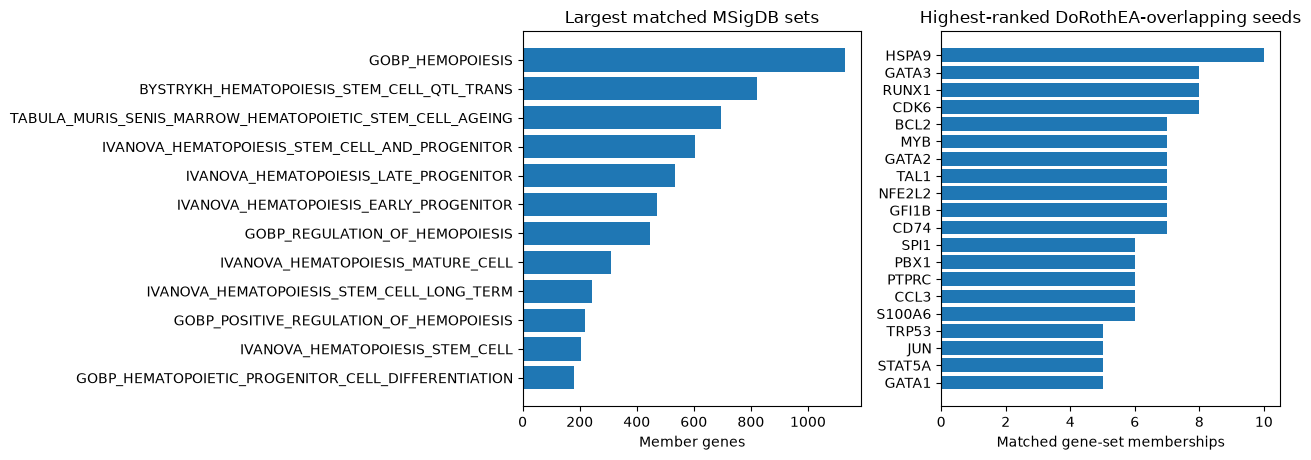

In [22]:
# Diagnostic visualizations of the MSigDB stage 
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
show_sets = matched_sets_df.head(12).iloc[::-1]
axes[0].barh(show_sets["gene_set"], show_sets["n_genes"])
axes[0].set_xlabel("Member genes")
axes[0].set_title("Largest matched MSigDB sets")
show_seeds = selected_seed_df.head(20).iloc[::-1]
axes[1].barh(show_seeds["gene"], show_seeds["n_matching_sets"])
axes[1].set_xlabel("Matched gene-set memberships")
axes[1].set_title("Highest-ranked DoRothEA-overlapping seeds")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "msigdb_matching_and_seeds.png", dpi=150, bbox_inches="tight")
plt.show()


### What “expand seeds into a network” actually means

Imagine two biologically annotated genes with no direct edge, `TF_A` and `TF_D`, connected through `TF_B` and `TF_C`. Restricting the network to the annotated genes alone would lose the actual signaling path. This stage therefore brings in **one-hop regulators and targets**, optionally keeps **short connecting paths** irrespective of direction during path search, and adds nearby genes that display **known activity changes** along the differentiation tree. The retained SIF preserves every original edge direction and sign.

The cap does **not** indiscriminately truncate the important anchors: `mandatory = seeds ∪ bridge_nodes ∪ extra_dynamic`, and the code raises an error if this mandatory set already exceeds the cap. Remaining slots are assigned to connected genes, then weakly connected components that contain no seed are discarded. **No SCC extraction happens yet.**

## 7. Expand MSigDB seeds into a reduced DoRothEA network

The selected seeds are now **automatically taken from the downloaded MSigDB**, rather than hard-coded. Include 1-hop upstream and downstream regulatory neighbors, optionally preserve short bridges and additional switching genes. Do not prefilter to the largest SCC: upstream genes outside an SCC may still matter. This network becomes the **candidate input** to BoNesis, not the final optimized selection.

**Important:** `MAX_CANDIDATE_GENES` is a resource guard. If the mandatory seeds, bridges, and dynamic additions exceed it, the notebook raises an explicit error rather than silently dropping seeds. Reduce `SEED_TOP_N`, `N_EXTRA_DYNAMIC`, or increase the cap.


#### Synthetic input preview — Neighbor expansion and bridge paths (synthetic)

The example explains why the algorithm can recover genes between two seed anchors even when those intermediate genes are not themselves MSigDB seeds.

In [23]:
import networkx as nx
demo_graph = nx.DiGraph()
demo_graph.add_edges_from([
    ("TF_A", "TF_B"), ("TF_B", "TF_C"), ("TF_C", "TF_D"),
    ("TF_D", "TF_E"), ("TF_F", "TF_B")
])
demo_seeds = {"TF_A", "TF_D"}
demo_neighbors = set(demo_seeds)
for demo_seed in demo_seeds:
    demo_neighbors.update(demo_graph.predecessors(demo_seed))
    demo_neighbors.update(demo_graph.successors(demo_seed))
demo_shortest = nx.shortest_path(demo_graph.to_undirected(), "TF_A", "TF_D")
print("Synthetic seeds:", sorted(demo_seeds))
print("One-hop seed neighborhood:", sorted(demo_neighbors))
print("Shortest weak bridge path:", " → ".join(demo_shortest))
print("With <=3 edges, TF_B and TF_C can be preserved as connecting genes.")


Synthetic seeds: ['TF_A', 'TF_D']
One-hop seed neighborhood: ['TF_A', 'TF_B', 'TF_C', 'TF_D', 'TF_E']
Shortest weak bridge path: TF_A → TF_B → TF_C → TF_D
With <=3 edges, TF_B and TF_C can be preserved as connecting genes.


In [24]:
# Build a reduced but seed-connected GRN using the original loaded DoRothEA graph.
# Keep direction/sign: we filter the original SIF, not reconstruct the edges from scratch.
FULL_SIF = Path("data/dorothea_ABC_20210707_TF.sif")
raw_sif = pd.read_csv(FULL_SIF, sep="\t", header=None, dtype=str, comment="#")
if raw_sif.shape[1] != 3:
    raise ValueError(f"Expected 3 SIF columns (source, sign, target), found {raw_sif.shape[1]}")
raw_sif.columns = ["source", "sign", "target"]
raw_sif["source"] = raw_sif["source"].str.strip()
raw_sif["target"] = raw_sif["target"].str.strip()
raw_sif["sign"] = raw_sif["sign"].str.strip()

full_graph = nx.DiGraph()
full_graph.add_nodes_from(standardized_dorothea.nodes())
full_graph.add_edges_from(standardized_dorothea.edges())

# Intersect the biological seed set with actual nodes in the full regulatory graph.
seeds = HEMATOPOIESIS_SEEDS & set(full_graph.nodes())
# Record any selected MSigDB seeds that the BoNesis-loaded graph cannot represent.
missing_seeds = HEMATOPOIESIS_SEEDS - seeds
print("Seeds present in GRN:", sorted(seeds))
print("Seeds missing from GRN:", sorted(missing_seeds))
if not seeds:
    raise ValueError("No hematopoiesis seeds appear in this GRN. Check gene symbols.")

# Compute variation only when both states have determined binary values.
# In the original input, -1/1 is the common BoNesis encoding; 0 represents ND.
all_values = [v for obs in standardized_observations.values()
              for v in obs.values() if not pd.isna(v)]
uses_minus_one = any(v == -1 for v in all_values)
determined = {-1, 1} if uses_minus_one else {0, 1}
# Define directed tree comparisons following the intended Nestorowa differentiation trajectory.
tree_edges = [("S1", "S0"), ("S0", "S2"), ("S0", "S3"),
              # Complete the five directed state-transition comparisons.
              ("S3", "S4"), ("S3", "S5")]

# Define a helper that checks if an observation contains a valid binary state.
def is_determined(value):
    # Return True only when the value is nonmissing and belongs to the determined-value set.
    return not pd.isna(value) and value in determined

# Create a dictionary to hold each gene's number of observed switches on five tree edges.
switch_count = {}
# Create a dictionary for the number of six states in which each gene has a determined value.
determined_count = {}
# Repeat the calculations for every regulator/target gene in the full network.
for gene in full_graph.nodes():
    # Read the gene's value from each requested state, returning None if absent.
    states = [standardized_observations.get(s, {}).get(gene) for s in
              ("S0", "S1", "S2", "S3", "S4", "S5")]
    # Count across how many states this gene has an observed OFF or ON value.
    determined_count[gene] = sum(is_determined(v) for v in states)
    # Start summing the number of tree edges on which this gene demonstrably changes.
    switch_count[gene] = sum(
        is_determined(standardized_observations.get(a, {}).get(gene))
        and is_determined(standardized_observations.get(b, {}).get(gene))
        and standardized_observations[a][gene] != standardized_observations[b][gene]
        for a, b in tree_edges
    )

# One-hop regulatory neighborhood (both upstream regulators and downstream targets).
neighbor_pool = set(seeds)
frontier = set(seeds)
for _ in range(NEIGHBOR_HOPS):
    next_nodes = set()
    for node in frontier:
        # Add regulators that act on this gene (upstream in-neighbors).
        next_nodes.update(full_graph.predecessors(node))
        # Add targets regulated by this gene (downstream out-neighbors).
        next_nodes.update(full_graph.successors(node))
    # Remove genes already seen at earlier hops.
    next_nodes -= neighbor_pool
    # Retain every new node for the eventual candidate pool.
    neighbor_pool.update(next_nodes)
    # Continue expansion from newly added nodes during the next hop.
    frontier = next_nodes

# Short weak paths between the independent seeds; original edge directions are retained.
# Create an initially empty set for genes that connect seeds through short paths.
bridge_nodes = set()
# Only search seed-to-seed bridges if this option is enabled.
if INCLUDE_SHORT_BRIDGES:
    #Ignore edge direction TEMPORARILY to find possible connecting paths between seeds.
    undirected = full_graph.to_undirected()
    #  Consider every unordered pair of distinct biological seeds.
    for a, b in itertools.combinations(sorted(seeds), 2):
        # Try to find a shortest path between this pair in the undirected projection.
        try:
            path = nx.shortest_path(undirected, a, b)
            #  Retain the path only if it has at most MAX_BRIDGE_EDGES links.
            if len(path) - 1 <= MAX_BRIDGE_EDGES:
                # Add every gene along this qualifying short path to the bridge pool.
                bridge_nodes.update(path)
        # Handle seed pairs that cannot be connected by any undirected path.
        except nx.NetworkXNoPath:
            pass

# Create a list of optional dynamically changing genes to rank.
possible_extra = []
for gene in full_graph.nodes():
    # Skip genes already nearby/bridging seeds or lacking an observed state switch.
    if gene in neighbor_pool or gene in bridge_nodes or switch_count[gene] == 0:
        continue
    # Start computing all direct regulators and targets of the optional gene.
    contact = (set(full_graph.predecessors(gene)) |
               #  Retain direct contacts only with the existing neighborhood or bridge nodes.
               set(full_graph.successors(gene))) & (neighbor_pool | bridge_nodes)
    # Only consider this additional gene if it connects to that existing pool.
    if contact:
        # Record its name, observed switching, contact count, and degree for priority ranking.
        possible_extra.append((gene, switch_count[gene], len(contact), full_graph.degree(gene)))
# Sort optional additions by switches, then seed-network contacts, then total degree.
possible_extra.sort(key=lambda x: (-x[1], -x[2], -x[3], x[0]))
extra_dynamic = {g for g, *_ in possible_extra[:N_EXTRA_DYNAMIC]}

# Keep seeds and short bridges, plus the reserved changing-gene candidates.
# Unite all seeds, short-bridge nodes, and reserved dynamic genes.
mandatory = seeds | bridge_nodes | extra_dynamic
# Check whether the mandatory nodes already exceed the candidate budget.
if len(mandatory) > MAX_CANDIDATE_GENES:
    raise ValueError(f"Mandatory genes ({len(mandatory)}) exceed MAX_CANDIDATE_GENES "
                     f"({MAX_CANDIDATE_GENES}); increase the cap or reduce additions.")

# Rank remaining seed-neighborhood genes by seed connections, observed changes, and degree.
remaining = neighbor_pool - mandatory
def priority(gene):
    # Start counting direct regulatory adjacencies between this gene and each seed.
    connected_to_seeds = sum(full_graph.has_edge(gene, s) or
                             full_graph.has_edge(s, gene) for s in seeds)
    # Prioritize connected-seed count first, observed switching second, total degree third.
    return (connected_to_seeds, switch_count[gene], full_graph.degree(gene))

# Sort remaining neighbors by the descending priority tuple and gene name as tie-break.
ranked = sorted(remaining, key=lambda g: tuple(-v for v in priority(g)) + (g,))
slots = MAX_CANDIDATE_GENES - len(mandatory)
# Fill available slots with top-ranked neighbors while never dropping mandatory genes.
chosen = mandatory | set(ranked[:slots])

# Do not force an SCC; only discard selected components with no remaining seed.
provisional_graph = full_graph.subgraph(chosen).copy()
keep = set()
for component in nx.weakly_connected_components(provisional_graph):
    if component & seeds:
        keep.update(component)
reduced_graph = provisional_graph.subgraph(keep).copy()


selected_sif = raw_sif.loc[
    raw_sif["source"].isin(reduced_graph.nodes()) &
    raw_sif["target"].isin(reduced_graph.nodes())
].copy()
if selected_sif.empty:
    raise ValueError("No regulatory edges remained. Try more seeds or a larger network cap.")
selected_sif_path = OUTPUT_DIR / "hematopoiesis_seed_network.sif"
selected_sif.to_csv(selected_sif_path, sep="\t", index=False, header=False)

# Import using the SAME settings as the original notebook.
# Create the reduced BoNesis influence graph using the original graph-loading options.
small_dorothea = bonesis.InfluenceGraph.from_sif(
    str(selected_sif_path), maxclause=8, allow_skipping_nodes=True, canonic=False
)
final_genes = set(small_dorothea.nodes())
small_observations = {
    state: {gene: value for gene, value in obs.items() if gene in final_genes}
    for state, obs in standardized_observations.items()
}

scores = pd.DataFrame({
    "gene": list(full_graph.nodes()),
    # Copy each gene's count of known switches across the five developmental edges.
    "switch_count": [switch_count[g] for g in full_graph.nodes()],
    # Copy each gene's count of determined state observations.
    "determined_states": [determined_count[g] for g in full_graph.nodes()],
    #Count incoming regulatory edges.
    "indegree": [full_graph.in_degree(g) for g in full_graph.nodes()],
    # Count outgoing regulatory edges.
    "outdegree": [full_graph.out_degree(g) for g in full_graph.nodes()],
    # Flag which genes were directly selected from MSigDB as biological seeds.
    "biological_seed": [g in seeds for g in full_graph.nodes()],
    # Flag genes kept to connect seed pairs by a short weak path.
    "bridge": [g in bridge_nodes for g in full_graph.nodes()],
    # Flag the reserved switching genes added from the transcriptomic observations.
    "extra_dynamic": [g in extra_dynamic for g in full_graph.nodes()],
    # Flag which full-domain genes survived into the BoNesis candidate domain.
    "in_reduced_graph": [g in final_genes for g in full_graph.nodes()],
})
scores.to_csv(OUTPUT_DIR / "candidate_gene_scores.csv", index=False)
(OUTPUT_DIR / "candidate_genes_before_optimization.txt").write_text("\n".join(sorted(final_genes)) + "\n")

print(f"Full GRN: {len(full_graph.nodes())} nodes, {len(full_graph.edges())} edges")
print(f"Seed neighborhood: {len(neighbor_pool)} genes")
print(f"Short bridge paths: {len(bridge_nodes)} genes")
print(f"Additional changing candidates: {len(extra_dynamic)} genes")
print(f"Reduced GRN: {len(small_dorothea.nodes())} nodes, "
      f"{len(small_dorothea.edges())} edges (BoNesis graph)")
print("Reduced network components (weak):",
      nx.number_weakly_connected_components(reduced_graph))
print("Final seeds retained:", sorted(seeds & final_genes))


for a, b in [("S2", "S4"), ("S2", "S5"), ("S4", "S5")]:

    differences = [g for g in final_genes
                   if is_determined(small_observations[a].get(g))
                   and is_determined(small_observations[b].get(g))
                   and small_observations[a][g] != small_observations[b][g]]
    print(f"Determined {a} vs {b} differences: {len(differences)}")


config_record = {
    "msigdb_release": MSIGDB_RELEASE,
    "msigdb_url": MSIGDB_URL,
    "search_terms": SEARCH_TERMS,
    "go_bp_only": GO_BP_ONLY,
    "min_matching_sets": MIN_MATCHING_SETS,
    "seed_top_n": SEED_TOP_N,
    "neighbor_hops": NEIGHBOR_HOPS,
    "include_short_bridges": INCLUDE_SHORT_BRIDGES,
    "max_bridge_edges": MAX_BRIDGE_EDGES,
    "n_extra_dynamic": N_EXTRA_DYNAMIC,
    "max_candidate_genes": MAX_CANDIDATE_GENES,
    "n_matched_sets": len(matching_sets),
    "n_matched_genes": len(gene_to_sets),
    "n_selected_seeds": len(HEMATOPOIESIS_SEEDS),
    "n_candidate_genes": len(final_genes)
}
(OUTPUT_DIR / "selection_settings.json").write_text(json.dumps(config_record, indent=2))


Seeds present in GRN: ['ANXA1', 'BCL2', 'CCL3', 'CD1D1', 'CD74', 'CDK6', 'GATA1', 'GATA2', 'GATA3', 'GFI1B', 'HSPA9', 'IL1RL1', 'JUN', 'KIT', 'MYB', 'NFE2L2', 'PBX1', 'PTPRC', 'RUNX1', 'S100A6', 'SMARCA2', 'SPI1', 'STAT5A', 'TAL1', 'TRP53']
Seeds missing from GRN: []
Full GRN: 1001 nodes, 2789 edges
Seed neighborhood: 252 genes
Short bridge paths: 67 genes
Additional changing candidates: 20 genes
Reduced GRN: 149 nodes, 637 edges (BoNesis graph)
Reduced network components (weak): 1
Final seeds retained: ['ANXA1', 'BCL2', 'CCL3', 'CD1D1', 'CD74', 'CDK6', 'GATA1', 'GATA2', 'GATA3', 'GFI1B', 'HSPA9', 'IL1RL1', 'JUN', 'KIT', 'MYB', 'NFE2L2', 'PBX1', 'PTPRC', 'RUNX1', 'S100A6', 'SMARCA2', 'SPI1', 'STAT5A', 'TAL1', 'TRP53']
Determined S2 vs S4 differences: 39
Determined S2 vs S5 differences: 26
Determined S4 vs S5 differences: 46


610

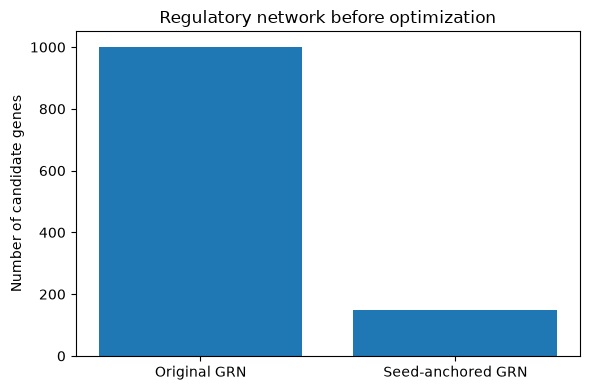

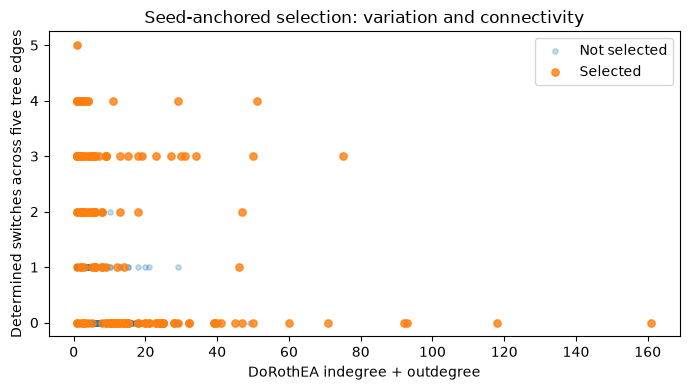

In [25]:
# Diagnostic plots: reduction and independent data-variation scores.
plt.figure(figsize=(6, 4))
plt.bar(["Original GRN", "Seed-anchored GRN"],
        [len(full_graph.nodes()), len(small_dorothea.nodes())])
plt.ylabel("Number of candidate genes")
plt.title("Regulatory network before optimization")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "candidate_network_sizes.png", dpi=160)
plt.show()

plt.figure(figsize=(7, 4))
not_selected = scores.loc[~scores["in_reduced_graph"]]
selected = scores.loc[scores["in_reduced_graph"]]
plt.scatter(not_selected["indegree"] + not_selected["outdegree"],
            not_selected["switch_count"], alpha=0.25, s=15, label="Not selected")
plt.scatter(selected["indegree"] + selected["outdegree"],
            selected["switch_count"], alpha=0.8, s=28, label="Selected")
plt.xlabel("DoRothEA indegree + outdegree")
plt.ylabel("Determined switches across five tree edges")
plt.title("Seed-anchored selection: variation and connectivity")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "selection_diagnostics.png", dpi=160)
plt.show()


In [26]:
# BoNesis now optimizes the smaller candidate regulatory network.
# Construct a BoNesis problem on the reduced candidate network and six restricted state observations.
bo = bonesis.BoNesis(small_dorothea, small_observations)

In [27]:
print(f"Full domain: {len(standardized_dorothea.nodes())} nodes, "
      f"{len(standardized_dorothea.edges())} edges")
print(f"Reduced domain used for optimization: {len(small_dorothea.nodes())} nodes, "
      f"{len(small_dorothea.edges())} edges")

Full domain: 1001 nodes, 2790 edges
Reduced domain used for optimization: 149 nodes, 637 edges


### Reading the dynamics specification

The six profiles do not represent a one-dimensional time series. The BoNesis expressions below constrain a **branching differentiation trajectory** with states S0–S5. `bo.obs('Sx')` refers to the partial observed gene activity of state Sx; `~bo.obs('Sx')` denotes a compatible ensemble of complete Boolean states, since unspecified genes can take either value. `bo.fixed(...)` requires a fixed point compatible with a terminal observation.

**This is a constraint model, not a numerical ODE simulation.** The solver seeks logical rules satisfying the specified relation between these states.


### Dynamics
<img src="img/trajectoire.png" alt="nestorowa stream trajectory" style="width:40%;"/>

In [30]:
# Declare a fixed point matching all determined entries in terminal observation S2.
s2 = bo.fixed(~bo.obs("S2"))
# Declare a fixed point matching terminal observation S4.
s4 = bo.fixed(~bo.obs("S4"))
# Declare a fixed point matching terminal observation S5.
s5 = bo.fixed(~bo.obs("S5"))
# Require the S2 and S4 fixed points to be different states.
s2 != s4
# Require the S5 and S4 fixed points to differ.
s5 != s4
# Require the S2 and S5 fixed points to differ
s2 != s5;

#### positive reachability

In [31]:
# Require a reachable progression from the S1-compatible observation via S0 to the S2 fixed point.
~bo.obs('S1') >= ~bo.obs('S0') >= s2
# Require a progression from the S0 observation via S3 to the S4 fixed point.
~bo.obs('S0') >= ~bo.obs('S3') >= s4
# Require the S5 fixed point to be reachable from an S3-compatible observation.
~bo.obs('S3') >= s5;

#### negative reachability

In [32]:
# Prohibit reachability of terminal fixed point S2 from states compatible with S3.
~bo.obs("S3") / s2;

### Original optimization objectives

The optimizer searches for compatible models on the **reduced input network**, maximizing included nodes and strong constants exactly as in the original notebook. The returned solution is only optimal within this smaller candidate network if Clingo proves optimality.

In [33]:
# Request the original optimization objective to maximize the number of included network nodes.
bo.maximize_nodes()
# Request the second objective to maximize strong constants while retaining the original ordering.
bo.maximize_strong_constants()

<bonesis.language.ManagedIface.__init__.<locals>.managed.<locals>.Managed at 0x7320ca39d400>

In [34]:
#  Construct a BoNesis solver view exposing nodes that are not assigned strong constant behavior.
view = bonesis.NonStrongConstantNodesView(bo, mode="opt")

In [35]:
# Choose an output filename for the standalone Clingo/BoNesis shell script.
standalone_script = OUTPUT_DIR / "maxnodes_maxstrongconstant_seed_filtered.sh"
# Serialize the BoNesis selection model and both objectives into an executable shell script.
view.standalone(output_filename=str(standalone_script))
# Print the generated script path for the separate optimization step.
print("Exported:", standalone_script)

Exported: msigdb_hematopoiesis_selection/maxnodes_maxstrongconstant_seed_filtered.sh


### Run Clingo automatically (optional)

This step executes the exported standalone script **once**, using all retained six-state constraints and both original optimization objectives. The 15-minute default limit is a test, not a guarantee of an optimum. For a proven optimum, the log must contain **`OPTIMUM FOUND`**. If your notebook kernel is on Windows instead of WSL, run the generated `.sh` from a WSL terminal.


In [36]:
import shutil
import subprocess
import time

# Do not execute the Clingo solver unless the user enabled the option earlier.
if RUN_OPTIMIZATION_IN_NOTEBOOK:
    if shutil.which("bash") is None or shutil.which("clingo") is None:
        print("Bash or Clingo not found in this Python environment.")
        print("Run this from your WSL terminal instead:")
        print(f"bash '{standalone_script}' --time-limit={OPTIMIZATION_TIME_LIMIT_SECONDS} "
              f"> '{OUTPUT_DIR / 'clingo_optimization.log'}' 2>&1")
    else:
        cmd = ["bash", str(standalone_script), f"--time-limit={OPTIMIZATION_TIME_LIMIT_SECONDS}"]
        print("Running:", " ".join(cmd))
        logfile = OUTPUT_DIR / "clingo_optimization.log"
        started = time.monotonic()
        with logfile.open("w") as log:
            result = subprocess.run(cmd, stdout=log, stderr=subprocess.STDOUT, check=False)
        seconds = time.monotonic() - started
        output = logfile.read_text(errors="replace")
        if "OPTIMUM FOUND" in output:
            status = "OPTIMUM FOUND"
        elif "UNSATISFIABLE" in output:
            status = "UNSATISFIABLE"
        elif "Answer:" in output:
            status = "FEASIBLE MODEL ONLY (OPTIMUM NOT CONFIRMED)"
        elif "UNKNOWN" in output or "INTERRUPTED" in output:
            status = "INTERRUPTED / TIME LIMIT"
        else:
            status = "NO MODEL REPORTED OR EXECUTION ERROR"
        print("Clingo status:", status)
        print("Clingo process exit code:", result.returncode)
        print(f"Elapsed time: {seconds:.1f} s")
        print("Full output:", logfile)
        print("Last lines:")
        print("\n".join(output.splitlines()[-12:]))
else:
    print("RUN_OPTIMIZATION_IN_NOTEBOOK=False; script exported but not executed.")
    print(f"Run in WSL: bash '{standalone_script}' --time-limit=900 "
          f"2>&1 | tee '{OUTPUT_DIR / 'clingo_optimization.log'}'")


RUN_OPTIMIZATION_IN_NOTEBOOK=False; script exported but not executed.
Run in WSL: bash 'msigdb_hematopoiesis_selection/maxnodes_maxstrongconstant_seed_filtered.sh' --time-limit=900 2>&1 | tee 'msigdb_hematopoiesis_selection/clingo_optimization.log'
